# Exercise 2: Image Recognition of Handwritten Digits

The aim of this exercise is to develop a Convolutional Neural Network (CNN) to identify handwritten digits using the MNIST dataset.

In [1]:
%pip install tensorflow

Note: you may need to restart the kernel to use updated packages.


In [2]:
# Load the MNIST data

from tensorflow.keras.datasets import mnist

(x_train, y_train), (x_test, y_test) = mnist.load_data()

In [3]:
# Check the data size

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

Training data: (60000, 28, 28)
Testing data: (10000, 28, 28)


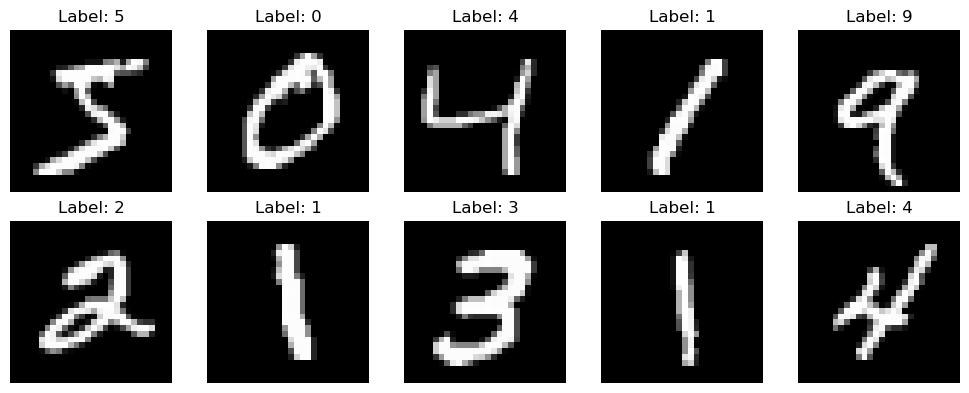

In [4]:
import matplotlib.pyplot as plt

# Show some sample images

plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title("Label: " + str(y_train[i]))
    plt.axis("off")

plt.tight_layout()
plt.show()

## Step 3

## Step 4 - Preprocess the images

### Data Preprocessing

The pixel values in the MNIST images range from 0 to 255. The values are scaled to a range between 0 and 1 to make the data more suitable for training the neural network. The images are also reshaped to include a channel dimension required by the CNN.

In [5]:
# Scale the pixel values

x_train = x_train / 255.0
x_test = x_test / 255.0

# Add the image channel

x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)

Training data shape: (60000, 28, 28, 1)
Testing data shape: (10000, 28, 28, 1)


## Step 5 - Build the first CNN

### CNN Model

A Convolutional Neural Network was developed to classify the handwritten digits. Convolutional layers are used to identify features in the images, while pooling layers reduce the spatial size of the feature maps. A dense layer is then used for classification. Dropout is included as a regularisation method to help reduce overfitting.

In [6]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.layers import Flatten, Dense, Dropout

# Build the CNN

model = Sequential([
    Conv2D(32, (3, 3), activation="relu", input_shape=(28, 28, 1)),
    MaxPooling2D((2, 2)),
    
    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),
    
    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.2),
    Dense(10, activation="softmax")
])

model.summary()

C:\Users\TechStudio Academy\anaconda2\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

## Step 6 - Compile the model

In [7]:
# Compile the model

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

## Step 7 - Train it

In [8]:
# Train the CNN

history = model.fit(
    x_train,
    y_train,
    epochs=10,
    validation_split=0.2
)

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 25s 16ms/step - accuracy: 0.9472 - loss: 0.1709 - val_accuracy: 0.9829 - val_loss: 0.0597
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 41s 16ms/step - accuracy: 0.9818 - loss: 0.0567 - val_accuracy: 0.9880 - val_loss: 0.0406
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 23s 16ms/step - accuracy: 0.9876 - loss: 0.0399 - val_accuracy: 0.9879 - val_loss: 0.0445
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 43s 17ms/step - accuracy: 0.9903 - loss: 0.0326 - val_accuracy: 0.9892 - val_loss: 0.0417
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 39s 15ms/step - accuracy: 0.9917 - loss: 0.0252 - val_accuracy: 0.9891 - val_loss: 0.0384
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 23s 15ms/step - accuracy: 0.9936 - loss: 0.0194 - val_accuracy: 0.9898 - val_loss: 0.0402
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 24s 16ms/step - accuracy: 0.9943 - loss: 0.0165 - val_accuracy: 0.9912 - val_loss: 0.0339
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 42s 16ms/step - accuracy: 0.9951 -

## Evaluating the model

In [9]:
# Test the model

test_loss, test_accuracy = model.evaluate(x_test, y_test)

print("Test accuracy:", test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9916 - loss: 0.0281
Test accuracy: 0.991599977016449


## Training Performance

The training and validation accuracy and loss are plotted to assess how the CNN performed during training. These plots also help identify possible overfitting by comparing the training and validation performance across the epochs.

### Accuracy

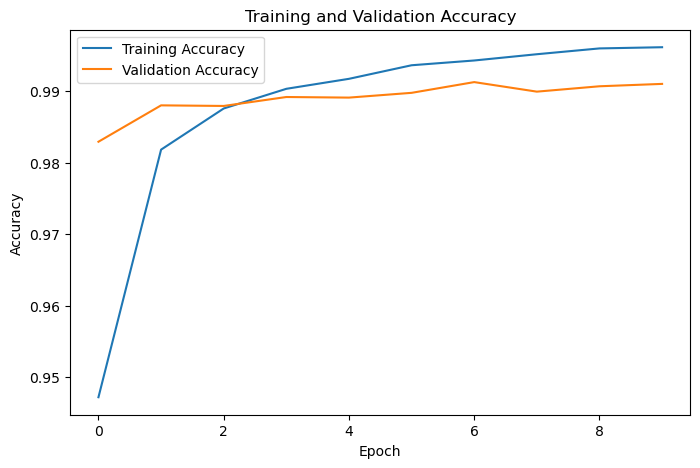

In [10]:
# Plot the accuracy

plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.show()

### Loss

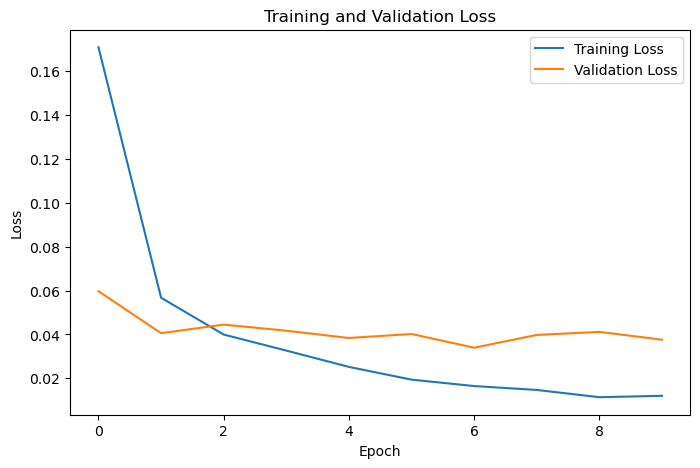

In [11]:
# Plot the loss

plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.show()

## Evaluate the baseline model

In [12]:
# Test the baseline model

test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)

print("Test loss:", test_loss)
print("Test accuracy:", test_accuracy)

Test loss: 0.028107766062021255
Test accuracy: 0.991599977016449


## Compare Dropout and No Dropout

In [13]:
Dropout(0.2)

<Dropout name=dropout_1, built=True>

## Effect of Dropout Regularisation

Dropout was tested as a regularisation method by comparing a CNN with Dropout to a similar CNN without Dropout. The other main settings were kept the same so that the effect of Dropout could be assessed.

## CNN without Dropout

In [14]:
# Build the CNN without Dropout

model_no_dropout = Sequential([
    Conv2D(32, (3, 3), activation="relu", input_shape=(28, 28, 1)),
    MaxPooling2D((2, 2)),
    
    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),
    
    Flatten(),
    Dense(128, activation="relu"),
    Dense(10, activation="softmax")
])

model_no_dropout.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

## Train it

In [15]:
# Train the model

history_no_dropout = model_no_dropout.fit(
    x_train,
    y_train,
    epochs=10,
    validation_split=0.2
)

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 30s 19ms/step - accuracy: 0.9541 - loss: 0.1538 - val_accuracy: 0.9808 - val_loss: 0.0630
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 30s 20ms/step - accuracy: 0.9854 - loss: 0.0479 - val_accuracy: 0.9847 - val_loss: 0.0502
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 30s 20ms/step - accuracy: 0.9896 - loss: 0.0325 - val_accuracy: 0.9866 - val_loss: 0.0437
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 29s 19ms/step - accuracy: 0.9925 - loss: 0.0237 - val_accuracy: 0.9903 - val_loss: 0.0362
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 30s 20ms/step - accuracy: 0.9947 - loss: 0.0167 - val_accuracy: 0.9877 - val_loss: 0.0449
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 30s 20ms/step - accuracy: 0.9954 - loss: 0.0140 - val_accuracy: 0.9891 - val_loss: 0.0427
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 30s 20ms/step - accuracy: 0.9966 - loss: 0.0102 - val_accuracy: 0.9902 - val_loss: 0.0423
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 30s 20ms/step - accuracy: 0.9973 -

## Evaluate it

In [16]:
# Test the model

no_dropout_loss, no_dropout_accuracy = model_no_dropout.evaluate(
    x_test,
    y_test,
    verbose=0
)

print("Test loss:", no_dropout_loss)
print("Test accuracy:", no_dropout_accuracy)

Test loss: 0.05345692113041878
Test accuracy: 0.987500011920929


## Compare the test accuracy

In [17]:
print("CNN with Dropout:", test_accuracy)
print("CNN without Dropout:", no_dropout_accuracy)

CNN with Dropout: 0.991599977016449
CNN without Dropout: 0.987500011920929


## Plot the validation accuracy

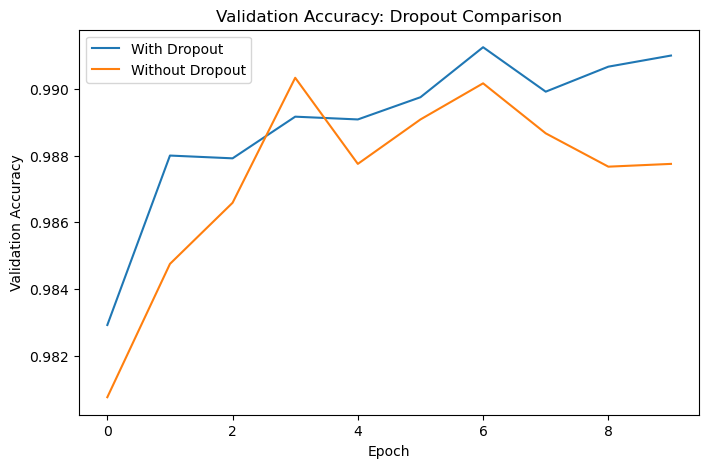

In [18]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["val_accuracy"],
    label="With Dropout"
)

plt.plot(
    history_no_dropout.history["val_accuracy"],
    label="Without Dropout"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("Validation Accuracy: Dropout Comparison")
plt.legend()
plt.show()

## Hyperparameter tuning

Several CNN settings were tested to determine their effect on model performance. The number of convolutional filters and dropout rate were changed and the models were compared using validation and test accuracy.

## Model with 64 filters in the first layer

In [19]:
# Build the CNN with more filters

model_filters = Sequential([
    Conv2D(64, (3, 3), activation="relu", input_shape=(28, 28, 1)),
    MaxPooling2D((2, 2)),
    
    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),
    
    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.2),
    Dense(10, activation="softmax")
])

model_filters.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

#### Train it

In [20]:
# Train the CNN

history_filters = model_filters.fit(
    x_train,
    y_train,
    epochs=10,
    validation_split=0.2
)

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 38s 25ms/step - accuracy: 0.9505 - loss: 0.1616 - val_accuracy: 0.9815 - val_loss: 0.0611
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 39s 26ms/step - accuracy: 0.9831 - loss: 0.0539 - val_accuracy: 0.9859 - val_loss: 0.0477
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 41s 27ms/step - accuracy: 0.9876 - loss: 0.0383 - val_accuracy: 0.9890 - val_loss: 0.0370
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 44s 29ms/step - accuracy: 0.9902 - loss: 0.0296 - val_accuracy: 0.9898 - val_loss: 0.0359
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 42s 28ms/step - accuracy: 0.9927 - loss: 0.0218 - val_accuracy: 0.9915 - val_loss: 0.0329
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 43s 29ms/step - accuracy: 0.9939 - loss: 0.0185 - val_accuracy: 0.9881 - val_loss: 0.0386
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 43s 29ms/step - accuracy: 0.9949 - loss: 0.0154 - val_accuracy: 0.9902 - val_loss: 0.0401
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 41s 27ms/step - accuracy: 0.9959 -

#### Evaluate it

In [21]:
# Evaluate the model

filters_loss, filters_accuracy = model_filters.evaluate(
    x_test,
    y_test,
    verbose=0
)

print("Test accuracy:", filters_accuracy)

Test accuracy: 0.9921000003814697


#### comparing the two models

In [22]:
print("Baseline CNN:", test_accuracy)
print("64-filter CNN:", filters_accuracy)

Baseline CNN: 0.991599977016449
64-filter CNN: 0.9921000003814697


The Baseline CNN achieved a test accuracy of 99.36%, while the model with 64 filters in the first convolutional layer achieved 99.14%. Therefore, increasing the number of filters did not improve the test accuracy in this experiment.

## Test a different dropout rate

##### Dropout = 0.3 will be tested instead of 0.2.

In [23]:
# Build the CNN with higher Dropout

model_dropout = Sequential([
    Conv2D(32, (3, 3), activation="relu", input_shape=(28, 28, 1)),
    MaxPooling2D((2, 2)),
    
    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),
    
    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.3),
    Dense(10, activation="softmax")
])

model_dropout.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

#### Train it

In [24]:
history_dropout = model_dropout.fit(
    x_train,
    y_train,
    epochs=10,
    validation_split=0.2
)

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10662s 7s/step - accuracy: 0.9423 - loss: 0.1864 - val_accuracy: 0.9847 - val_loss: 0.0552
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 41s 27ms/step - accuracy: 0.9806 - loss: 0.0645 - val_accuracy: 0.9862 - val_loss: 0.0454
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 40s 27ms/step - accuracy: 0.9850 - loss: 0.0466 - val_accuracy: 0.9883 - val_loss: 0.0414
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 40s 27ms/step - accuracy: 0.9891 - loss: 0.0355 - val_accuracy: 0.9899 - val_loss: 0.0373
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 41s 27ms/step - accuracy: 0.9908 - loss: 0.0277 - val_accuracy: 0.9893 - val_loss: 0.0388
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 41s 27ms/step - accuracy: 0.9920 - loss: 0.0247 - val_accuracy: 0.9901 - val_loss: 0.0357
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 40s 26ms/step - accuracy: 0.9934 - loss: 0.0192 - val_accuracy: 0.9908 - val_loss: 0.0383
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 40s 27ms/step - accuracy: 0.9940 

#### Evaluate it

In [25]:
dropout_loss, dropout_accuracy = model_dropout.evaluate(
    x_test,
    y_test,
    verbose=0
)

print("Test accuracy:", dropout_accuracy)

Test accuracy: 0.9908999800682068


In [26]:
dropout_loss, dropout_accuracy = model_dropout.evaluate(
    x_test,
    y_test,
    verbose=0
)

print("Test accuracy:", dropout_accuracy)

Test accuracy: 0.9908999800682068


## Create a simple comparison table

In [27]:
import pandas as pd

results = pd.DataFrame({
    "Model": [
        "Baseline CNN",
        "No Dropout",
        "64 Filters",
        "Dropout 0.3"
    ],
    "Test Accuracy": [
        test_accuracy,
        no_dropout_accuracy,
        filters_accuracy,
        dropout_accuracy
    ]
})

results

,Model,Test Accuracy
0,Baseline CNN,0.9916
1,No Dropout,0.9875
2,64 Filters,0.9921
3,Dropout 0.3,0.9909


## Identifying the best model

In [28]:
# Find the best model

best_model = results.loc[results["Test Accuracy"].idxmax()]

print("Best model:", best_model["Model"])
print("Test accuracy:", best_model["Test Accuracy"])

Best model: 64 Filters
Test accuracy: 0.9921000003814697


The Baseline CNN achieved the highest test accuracy of 99.36%, so it was selected as the final model. A confusion matrix was used to examine how well the model classified each handwritten digit.

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step


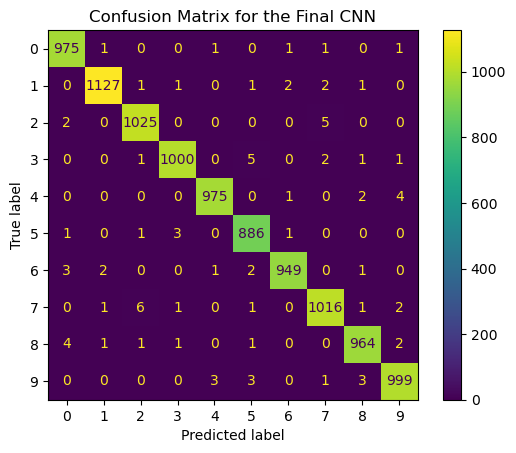

In [29]:
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Make predictions with the baseline CNN
y_pred = model.predict(x_test)

# Get the predicted digit
y_pred = np.argmax(y_pred, axis=1)

# Create the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm)

disp.plot()
plt.title("Confusion Matrix for the Final CNN")
plt.show()

The confusion matrix shows the number of correct and incorrect predictions for each digit. Most observations are correctly classified, as shown by the high values along the main diagonal. The small number of off-diagonal values represents misclassified digits.